# 2020 — Vision Transformer (ViT)

**Paper:** Alexey Dosovitskiy et al., *"An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale"* (2020).

Treat an image as a **sequence of patches**:
1. split the image into $P\times P$ patches and flatten each one
2. linearly project each patch to a $d$-dim token (the same as a conv with kernel = stride = $P$)
3. prepend a learnable **[CLS] token** and add learned **position embeddings**
4. run a standard Transformer encoder and classify from [CLS]

ViT has much weaker inductive biases than a CNN (no locality or translation equivariance built in), so it needs more data or augmentation. Given enough of either it matches or beats CNNs, and it is the image encoder in CLIP, multimodal LLMs and diffusion transformers.

![Diagram: Vision Transformer (Dosovitskiy et al., 2020)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/49_2020_vision_transformer.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]
P = 4                                     # 16x16 image -> 4x4 grid of 4x4 patches = 16 tokens

In [3]:
class Block(nn.Module):
    def __init__(self, d, h, p=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, h, dropout=p, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(p), nn.Linear(4 * d, d))
    def forward(self, x):
        y = self.ln1(x)
        a, w = self.attn(y, y, y, need_weights=True, average_attn_weights=False)
        self.attn_weights = w.detach()
        x = x + a
        return x + self.mlp(self.ln2(x))

class ViT(nn.Module):
    def __init__(self, img=16, patch=4, d=96, depth=4, heads=4, n_classes=10):
        super().__init__()
        self.n = (img // patch) ** 2
        self.patch_embed = nn.Conv2d(1, d, patch, stride=patch)            # "linear projection of flattened patches"
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, self.n + 1, d) * 0.02)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(depth)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, n_classes)
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)                 # (B, 16, d)
        x = torch.cat([self.cls.expand(len(x), -1, -1), x], 1) + self.pos
        for b in self.blocks: x = b(x)
        return self.head(self.ln(x[:, 0]))

def augment(x):
    pad = F.pad(x, (2, 2, 2, 2)); i, j = np.random.randint(0, 5, 2)
    return pad[:, :, i:i + 16, j:j + 16]

model = ViT().to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e3:.0f}K")
epochs = 40
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=epochs * ((len(Xtr) + 63) // 64))
for ep in range(epochs):
    model.train(); perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), 64):
        idx = perm[i:i + 64]
        loss = F.cross_entropy(model(augment(Xtr[idx])), ytr[idx], label_smoothing=0.1)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if ep % 10 == 9:
        model.eval()
        with torch.no_grad(): acc = (model(Xte).argmax(1) == yte).float().mean().item()
        print(f"epoch {ep + 1}  loss {loss.item():.3f}  test acc {acc:.3f}")

parameters: 452K


epoch 10  loss 1.844  test acc 0.403


epoch 20  loss 0.680  test acc 0.872


epoch 30  loss 0.664  test acc 0.919


epoch 40  loss 0.704  test acc 0.939


## What did ViT learn?
**Left:** similarity between learned position embeddings. Each patch's embedding is most similar to its spatial neighbours, so the model has *learned* the 2-D layout. **Right:** attention from [CLS] to the patches in the last layer.

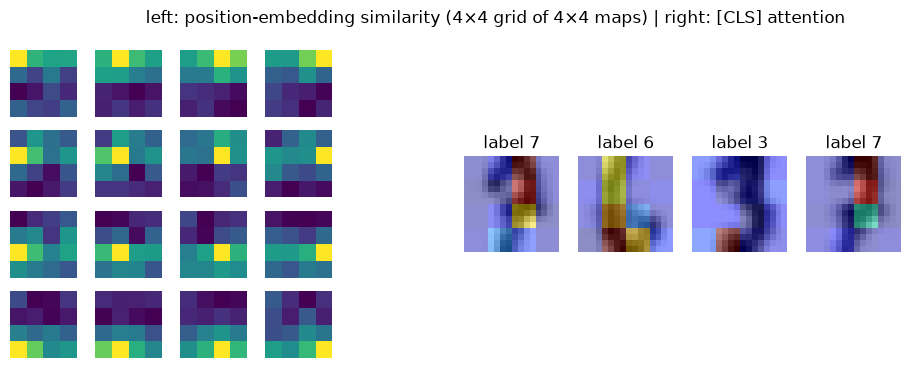

In [4]:
pos = F.normalize(model.pos[0, 1:].detach(), dim=-1).cpu()
sim = (pos @ pos.T).view(4, 4, 4, 4)
fig = plt.figure(figsize=(13, 4))
for k in range(16):
    ax = fig.add_subplot(4, 12, (k // 4) * 12 + k % 4 + 1); ax.imshow(sim[k // 4, k % 4], cmap="viridis"); ax.axis("off")
model.eval()
with torch.no_grad(): model(Xte[:4])
for j in range(4):
    att = model.blocks[-1].attn_weights[j].mean(0)[0, 1:].view(4, 4).cpu()       # CLS -> patches, head-averaged
    ax = fig.add_subplot(1, 9, 5 + j); ax.imshow(Xte[j, 0].cpu(), cmap="gray_r")
    ax.imshow(F.interpolate(att[None, None], size=16, mode="nearest")[0, 0], cmap="jet", alpha=0.45); ax.axis("off")
    ax.set_title(f"label {yte[j].item()}")
plt.suptitle("left: position-embedding similarity (4×4 grid of 4×4 maps) | right: [CLS] attention"); plt.show()

## Takeaways
- On a dataset this small, ViT trails the CNNs in this repo (LeNet ≈ 97%, ResNet ≈ 99%). That is the missing inductive bias at work. With hundreds of millions of images (or strong augmentation/distillation, as in DeiT 2021) the ranking flips.
- Patches + Transformer is now the default image encoder in multimodal models.